Loading data...
Train: (21250, 200) | Val: (3750, 200) | Test: (25000, 200)


Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_22 (Embedding)        │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 200, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_37 (SimpleRNN)       │ (None, 200, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_38 (SimpleRNN)       │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,297,633 (4.95 MB)

 Trainable params: 1,297,633 (4.95 MB)

 Non-trainable params: 0 (0.00 B)

Training...
Epoch 1/25
333/333 ━━━━━━━━━━━━━━━━━━━━ 28s 54ms/step - accuracy: 0.6335 - loss: 0.6233 - val_accuracy: 0.6811 - val_loss: 0.6488 - learning_rate: 0.0010
Epoch 2/25
333/333 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.8368 - loss: 0.4087 - val_accuracy: 0.7819 - val_loss: 0.5038 - learning_rate: 0.0010
Epoch 3/25
333/333 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.8581 - loss: 0.3606 - val_accuracy: 0.8427 - val_loss: 0.3864 - learning_rate: 0.0010
Epoch 4/25
333/333 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8833 - loss: 0.3100 - val_accuracy: 0.8411 - val_loss: 0.4119 - learning_rate: 0.0010
Epoch 5/25
333/333 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9033 - loss: 0.2638
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
333/333 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9045 - loss: 0.2579 - val_accuracy: 0.8152 - val_loss: 0.4436 - learning_rate: 0.0010
Epoch 6/25
333/333 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 

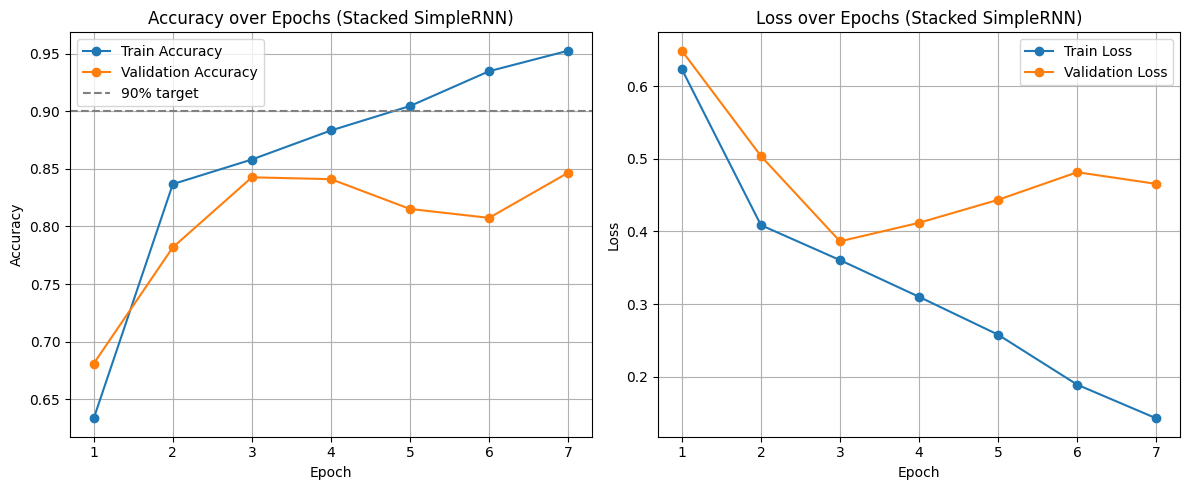

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Embedding, SimpleRNN, Dense,
                                     Dropout, SpatialDropout1D)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ------------------------------------------------------------
# 0. Reproducibility
# ------------------------------------------------------------
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# ------------------------------------------------------------
# 1. Config
# ------------------------------------------------------------
VOCAB_SIZE = 10000
MAX_LENGTH = 200      # shorter sequences = easier for a SimpleRNN
EMBED_DIM = 128
BATCH_SIZE = 64
EPOCHS = 25

# ------------------------------------------------------------
# 2. Load + preprocess
# ------------------------------------------------------------
print("Loading data...")
(X_train_full, y_train_full), (X_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

# PRE padding/truncating: real words sit at the END of the sequence, so the
# final RNN state is built from real words, not a long run of zeros.
X_train_full = pad_sequences(X_train_full, maxlen=MAX_LENGTH, padding='pre', truncating='pre')
X_test = pad_sequences(X_test, maxlen=MAX_LENGTH, padding='pre', truncating='pre')

# Validation comes from TRAIN, so the test set stays untouched until the end
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.15, stratify=y_train_full, random_state=SEED
)
print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

# ------------------------------------------------------------
# 3. Model (SimpleRNN only, no Bidirectional)
# ------------------------------------------------------------
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, mask_zero=True),
    SpatialDropout1D(0.2),

    SimpleRNN(64, return_sequences=True, dropout=0.2, activation='tanh'),
    SimpleRNN(32, dropout=0.2, activation='tanh'),

    Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(
    # clipnorm is important for SimpleRNN: it stops exploding gradients
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.build(input_shape=(None, MAX_LENGTH))
model.summary()

# ------------------------------------------------------------
# 4. Callbacks
# ------------------------------------------------------------
callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    ModelCheckpoint('best_rnn_model.keras', monitor='val_loss', save_best_only=True),
]

# ------------------------------------------------------------
# 5. Train
# ------------------------------------------------------------
print("Training...")
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=callbacks
)

# ------------------------------------------------------------
# 6. Final evaluation (test set used ONCE, here)
# ------------------------------------------------------------
print("\n--- Final Evaluation ---")
train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Train Accuracy: {train_acc:.4f} | Loss: {train_loss:.4f}")
print(f"Val   Accuracy: {val_acc:.4f} | Loss: {val_loss:.4f}")
print(f"Test  Accuracy: {test_acc:.4f} | Loss: {test_loss:.4f}")

y_prob = model.predict(X_test, batch_size=256, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive'], digits=4))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

# ------------------------------------------------------------
# 7. Plots
# ------------------------------------------------------------
epochs_ran = range(1, len(history.history['loss']) + 1)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_ran, history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(epochs_ran, history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.axhline(0.90, color='gray', linestyle='--', label='90% target')
plt.title('Accuracy over Epochs (Stacked SimpleRNN)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, history.history['loss'], label='Train Loss', marker='o')
plt.plot(epochs_ran, history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Loss over Epochs (Stacked SimpleRNN)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Run in a NEW notebook cell AFTER training finishes.
# Uses variables already in memory: model, VOCAB_SIZE, MAX_LENGTH

import re
import numpy as np
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

word_index = imdb.get_word_index()

def encode(text):
    words = re.findall(r"[a-z0-9']+", text.lower())
    ids = [1]  # start token
    for w in words:
        idx = word_index.get(w)
        ids.append(2 if (idx is None or idx + 3 >= VOCAB_SIZE) else idx + 3)
    return ids

positive_sentences = [
    "I absolutely loved this movie, every scene was beautifully crafted and the ending left me in tears.",
    "A brilliant film with outstanding performances and a story that stays with you long after the credits roll.",
    "Funny, charming and surprisingly emotional, this is easily one of the best comedies I have seen in years.",
    "The cinematography is breathtaking and the soundtrack perfectly matches the mood of every scene.",
    "I was hooked from the first minute and could not look away until the very end.",
    "Even though it starts slowly, the second half is gripping and the finale is unforgettable.",
    "I didn't expect much, but I walked out of the theater smiling and wanting to watch it again.",
    "Not a single scene felt wasted, and the characters felt real, warm and deeply human.",
    "A heartwarming story about friendship that made me laugh out loud and cry within the same ten minutes.",
    "The lead actor delivers a career-best performance and carries the whole film with ease.",
    "This is smart, stylish and endlessly entertaining, and it deserves every bit of its praise.",
    "I can't say I didn't enjoy it; the humor landed and the cast had wonderful chemistry.",
    "What a delightful surprise, clever writing, great pacing and a perfect ending.",
    "The director clearly loves the material, and that passion shines through in every frame.",
    "Despite a modest budget, the film looks gorgeous and tells a powerful, moving story.",
    "One of those rare movies that is both a thrilling ride and a thoughtful piece of art.",
    "The dialogue is sharp and witty, and I laughed more than I have at any comedy this year.",
    "Beautifully acted, wonderfully written and directed with real care, I highly recommend it.",
    "At first I thought it would be a mess, but it turned into a wonderfully inventive adventure.",
    "The ending was perfect, emotional without being cheesy, and it tied everything together beautifully.",
    "A great family movie that kids and adults can both enjoy from start to finish.",
    "The suspense is masterfully built, and the twist genuinely caught me off guard in the best way.",
    "I loved the characters so much that I did not want the movie to end.",
    "Stunning visuals, a gorgeous score and a story with real heart make this a must see.",
    "Although it has a few flaws, the sheer charm and energy of the film won me over completely.",
    "The performances are superb across the board, and the supporting cast steals every scene they are in.",
    "This film is a true classic, and it holds up wonderfully even after many years.",
    "Pure joy from beginning to end, with a fantastic cast and a script full of great lines.",
    "I went in with low expectations and came out thoroughly impressed by how good it was.",
    "An inspiring and touching story, told with honesty, warmth and a wonderful sense of humor.",
    "The action sequences are thrilling and well shot, and the story actually makes you care about the people.",
    "Intelligent, moving and beautifully paced, this is exactly the kind of movie I wish there were more of.",
    "It's not perfect, but it is so sincere and well made that I could not help loving it.",
    "A wonderful romance with real chemistry between the leads and a script that avoids every cliche.",
    "The film manages to be both hilarious and deeply touching, which is not an easy thing to pull off.",
    "I would happily watch this again tomorrow, it is that good.",
    "Gripping from the opening scene, with a superb lead performance and a satisfying conclusion.",
    "The animation is gorgeous, the humor works for everyone and the emotional moments really land.",
    "Few films have moved me like this one, and I am still thinking about it days later.",
    "A clever, fast and endlessly rewatchable thriller with a fantastic final twist.",
    "Every actor is perfectly cast, and the story is told with confidence, wit and heart.",
    "Surprisingly good, with a smart script, strong acting and a finale that earns its emotion.",
    "I laughed, I cried, and I left the cinema feeling truly happy, so what more could you ask for.",
    "The story is simple but powerful, and the performances make it feel completely authentic.",
    "This is a superb piece of filmmaking, tense, intelligent and immaculately acted.",
    "What a pleasure to watch, warm, funny and full of wonderfully drawn characters.",
    "Although I expected a typical sequel, it surprised me with fresh ideas and real emotional depth.",
    "The film's message is moving, the pacing is excellent and the music is unforgettable.",
    "An absolute triumph, one of the finest movies of the decade in my opinion.",
    "I never once checked my watch, because the story was far too engaging to ignore.",
]

negative_sentences = [
    "This was the worst movie I have seen in years, a complete waste of time and money.",
    "The plot makes no sense, the acting is wooden and the dialogue is painfully bad.",
    "I was bored out of my mind and almost fell asleep halfway through.",
    "Despite a great cast, the script is lazy and the whole film feels like a cheap cash grab.",
    "I wanted to like it, but every scene dragged and the ending was a total letdown.",
    "The special effects look awful and the story is predictable from the very first scene.",
    "A dull, lifeless mess with characters I could not care less about.",
    "Terrible acting, terrible writing and a runtime that feels endless.",
    "The trailer promised excitement, but the film itself delivers almost nothing worth watching.",
    "I hated the ending, it was rushed, confusing and made the whole story pointless.",
    "With a premise this strong it should have been great, but the director completely ruined it.",
    "Not a single joke landed, and I spent the entire movie waiting for it to be over.",
    "Painfully slow, badly edited and so poorly written that I almost walked out of the theater.",
    "The characters are annoying, the story is a mess and the film is a pure disaster.",
    "Although the visuals are pretty, the film is empty, boring and far too long.",
    "I cannot recommend this to anyone, it is just a boring and forgettable waste of two hours.",
    "The dialogue is cringeworthy and the performances are some of the worst I have ever seen.",
    "A lazy sequel that adds nothing new and ruins everything that made the original good.",
    "Oh great, another predictable remake where nothing makes sense, exactly what the world needed.",
    "The pacing is terrible, the humor is flat and the plot holes are impossible to ignore.",
    "I kept hoping it would get better, but it only got worse with every passing minute.",
    "A forgettable, badly made thriller with no tension and a laughably stupid twist.",
    "The movie is not funny, not scary and not even slightly interesting.",
    "I have never been so disappointed by a film that had so much potential.",
    "Awful script, awful editing and an ending so bad that it made me angry.",
    "This film is a boring slog, and I regret every minute I spent watching it.",
    "The acting is flat, the music is annoying and the story goes absolutely nowhere.",
    "It had one good idea and wasted it on a clumsy, tedious and unbelievably dull plot.",
    "I wouldn't recommend this to anyone unless you enjoy watching nothing happen for two hours.",
    "The film tries so hard to be clever, but it just ends up confusing, pretentious and tiresome.",
    "Cheap, ugly and badly acted, this is one of the worst horror movies I have ever sat through.",
    "A masterpiece of boredom: beautifully shot, impeccably cast and completely lifeless.",
    "The humor is crude, the characters are unlikable and the story is a complete mess.",
    "I can't say I enjoyed a single minute of it.",
    "The more the movie went on, the more I wanted to leave and never think about it again.",
    "The director has made a mess of what should have been a simple, strong story.",
    "Everything about this movie feels fake, forced and utterly pointless.",
    "Weak plot, weak acting and a script that sounds like it was written in ten minutes.",
    "I laughed only once, and that was at how bad the special effects were.",
    "A tedious and badly paced film that mistakes being loud for being exciting.",
    "The ending was so stupid and unsatisfying that it ruined the entire movie for me.",
    "This is the kind of film that makes you want your money back before the first half hour is over.",
    "Even the great actors could not save this ridiculous, poorly written and joyless film.",
    "The story is a confusing jumble of bad ideas, and nothing about it works.",
    "I expected a fun adventure and got a dull, lifeless and embarrassingly bad film instead.",
    "Nothing about this movie is original, and everything about it is boring.",
    "An overlong, overhyped and underwhelming film that fails on almost every level.",
    "The film is a total waste of a talented cast, with a script that gives them nothing to work with.",
    "Sloppy, shallow and badly directed, it is hard to believe anyone approved this.",
    "I stared at the clock the whole time, because the movie was that slow and that dull.",
]

# ------------------------------------------------------------
# Build the test set (True = should be positive, False = should be negative)
# ------------------------------------------------------------
sentences = positive_sentences + negative_sentences
is_positive = np.array([True] * len(positive_sentences) + [False] * len(negative_sentences))

seqs = [encode(s) for s in sentences]
padded = pad_sequences(seqs, maxlen=MAX_LENGTH, padding='pre', truncating='pre')
probs = model.predict(padded, batch_size=64, verbose=0).ravel()
pred_positive = probs > 0.5
correct = pred_positive == is_positive

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------
n = len(sentences)
print(f"Overall accuracy : {correct.sum()}/{n} = {correct.mean()*100:.1f}%")
print(f"Positive correct : {correct[is_positive].sum()}/{is_positive.sum()}")
print(f"Negative correct : {correct[~is_positive].sum()}/{(~is_positive).sum()}")

tp = (pred_positive & is_positive).sum()
tn = (~pred_positive & ~is_positive).sum()
fp = (pred_positive & ~is_positive).sum()
fn = (~pred_positive & is_positive).sum()
print(f"\nConfusion matrix (rows = true, cols = predicted)")
print(f"              pred NEG   pred POS")
print(f"true NEG      {tn:>8}   {fp:>8}")
print(f"true POS      {fn:>8}   {tp:>8}")

conf = np.where(pred_positive, probs, 1 - probs)
print(f"\nAverage confidence when right: {conf[correct].mean()*100:.1f}%")
print(f"Average confidence when wrong: {conf[~correct].mean()*100:.1f}%")

print("\n=== Wrong predictions ===")
for i in np.where(~correct)[0]:
    should = "POSITIVE" if is_positive[i] else "NEGATIVE"
    got = "POSITIVE" if pred_positive[i] else "NEGATIVE"
    print(f"[{i+1:>3}] should be {should}, got {got} ({conf[i]*100:.1f}%)  {sentences[i]}")

Overall accuracy : 95/100 = 95.0%
Positive correct : 48/50
Negative correct : 47/50

Confusion matrix (rows = true, cols = predicted)
              pred NEG   pred POS
true NEG            47          3
true POS             2         48

Average confidence when right: 85.4%
Average confidence when wrong: 65.1%

=== Wrong predictions ===
[  7] should be POSITIVE, got NEGATIVE (74.4%)  I didn't expect much, but I walked out of the theater smiling and wanting to watch it again.
[ 50] should be POSITIVE, got NEGATIVE (52.0%)  I never once checked my watch, because the story was far too engaging to ignore.
[ 54] should be NEGATIVE, got POSITIVE (55.8%)  Despite a great cast, the script is lazy and the whole film feels like a cheap cash grab.
[ 61] should be NEGATIVE, got POSITIVE (63.1%)  With a premise this strong it should have been great, but the director completely ruined it.
[ 85] should be NEGATIVE, got POSITIVE (80.4%)  The more the movie went on, the more I wanted to leave and never 